In [1]:
# ---
# jupyter:
#   jupytext:
#     text_representation:
#       extension: .py
#       format_name: percent
#       format_version: '1.3'
#       jupytext_version: 1.19.6
#   kernelspec:
#     display_name: jaspy
#     language: python
#     name: jaspy
# ---

# NB 07 Spatial aggregation robustness

Parametric models only (the seven candidate families). Lake pixels are split into 9 and 36 equal-count parts (partial 3x3 and 6x6); a 2 x 2 design varies the scale of the responses (precipitation, wind) and of the divergence covariate. AR/GARCH are fitted once on the full sample (per-fold fits were unstable); the PIT, regime split and copula fits are train-only on each of the four blocked folds.

## Imports

In [2]:
import os
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["NUMEXPR_NUM_THREADS"] = "1"

import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from run_support import load_artifact, save_artifact, SMOKE   # SMOKE (THESIS_SMOKE=1): 2 parts, 2 GARCH starts
from data_split import make_blocked_folds, check_blocked_folds
from spatial_aggregation import (make_partitions, part_series, filter_series, SpatialRunner, iter_unit_cases,
                                 summary_table, reading_guide, plot_summary_top, plot_summary_bottom)
import io, time, contextlib
import plotting_core
import plotting_lake
plotting_core.configure("07_sensitivity_analysis_spatial_aggregation")      # figures -> "Images 07_sensitivity_analysis_spatial_aggregation"
import reporting_tables
reporting_tables.configure("07_sensitivity_analysis_spatial_aggregation")          # tables  -> "Tables 07_sensitivity_analysis_spatial_aggregation"
TABLES_DIR = reporting_tables.LATEX_DIR

## Load the lake pixels and the lake-mean baseline

In [3]:
art = load_artifact("preprocessing")
lakepts = art['lakepts']                    # dict: variable -> (n_t, n_pixels)
lat_lake, lon_lake = np.asarray(art['lat_lake']), np.asarray(art['lon_lake'])
time_valid = art['time_valid']
common_idx = pd.DatetimeIndex(art['common_idx'])
purge_final = int(art['purge_final'])
N_PIX = len(lat_lake)
n_pos = len(common_idx)
print(f"{N_PIX} lake pixels, {lakepts['precip'].shape[0]} time steps, usable n={n_pos}, purge={purge_final}")

folds = make_blocked_folds(n_pos, purge=purge_final)
check_blocked_folds(folds, n_pos, purge=purge_final)

# Sanity check: the pixel-mean series must reproduce the lake-mean series of NB00.
lake_recomputed = part_series(lakepts, np.ones(N_PIX, bool))
for v, key in (('precip', 'precip_all_grid'), ('wind', 'wind_all_grid'), ('div', 'div_all_grid')):
    ref = np.asarray(art[key]).astype(float)
    rel = np.nanmax(np.abs(lake_recomputed[v] - ref) / np.maximum(np.abs(ref), 1e-9))
    print(f"lake mean {v}: max relative difference to NB00 = {rel:.2e}")
    assert rel < 1e-4, f"{v}: pixel-mean series does not reproduce the NB00 lake mean"

1665 lake pixels, 2928 time steps, usable n=2884, purge=97
lake mean precip: max relative difference to NB00 = 2.34e-06
lake mean wind: max relative difference to NB00 = 0.00e+00
lake mean div: max relative difference to NB00 = 0.00e+00


## Partitions (equal pixel counts)

9 parts, pixels per part: [185, 185, 185, 185, 185, 185, 185, 185, 185]
36 parts, pixels per part: [47, 47, 46, 46, 46, 46, 47, 47, 46, 46, 46, 46, 47, 47, 46, 46, 46, 46, 47, 46, 46, 46, 46, 46, 47, 46, 46, 46, 46, 46, 47, 46, 46, 46, 46, 46]


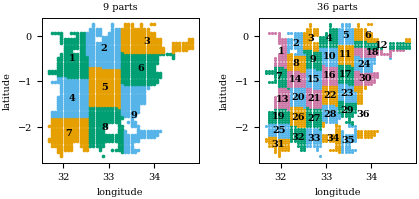

In [4]:
PARTS = {9: make_partitions(lat_lake, lon_lake, 9), 36: make_partitions(lat_lake, lon_lake, 36)}
for k, masks in PARTS.items():
    print(f"{k} parts, pixels per part: {[int(m.sum()) for m in masks]}")

import figure_recipes as FR
FR.spatial_partitions(PARTS, lon_lake, lat_lake)


## Lake-mean series (baseline)

Partial series are built and filtered inside the parallel workers.

In [5]:
p, w, d, HOURS = filter_series(art['precip_all_grid'], art['wind_all_grid'], art['div_all_grid'], time_valid)
SERIES = {'lake': (p, w, d)}      # NB00 lake-mean arrays, so the baseline is identical to the main pipeline
assert common_idx.isin(p.index).all() and common_idx.isin(w.index).all() and common_idx.isin(d.index).all()
print("lake series filtered")

lake series filtered


## Run the 2 x 2 design

Baseline (lake, lake), then for every part (lake covariate, part responses), (part covariate, lake responses), (part, part): 1 + 9x3 + 36x3 = 136 parameter sets. Parts run in parallel, one core each (the lake-wide AR/GARCH fits are shared). Results are appended to a CSV after every part, so an interrupted run resumes.

In [6]:
RESULT_CSV = os.path.join(TABLES_DIR, "spatial_aggregation_results.csv")
LOG_TXT = os.path.join(TABLES_DIR, "spatial_aggregation_garch_log.txt")
done = pd.read_csv(RESULT_CSV) if os.path.exists(RESULT_CSV) else pd.DataFrame()
done_keys = set(done['case_key'].unique()) if len(done) else set()

runner = SpatialRunner(SERIES, HOURS, common_idx, folds, n_starts=(2 if SMOKE else 20), ar_garch_sample='full')
t_start = time.time()

# Baseline (lake, lake)
if "baseline" not in done_keys:
    buf = io.StringIO()
    with contextlib.redirect_stdout(buf):
        df = runner.run_case("lake", "lake", dict(scale="lake", n_pixels=N_PIX, part=0,
                                                  case="(lake, lake)", case_key="baseline"))
    with open(LOG_TXT, "a") as fh:
        fh.write(f"=== baseline\n{buf.getvalue()}\n")
    done = pd.concat([done, df], ignore_index=True)
    done.to_csv(RESULT_CSV, index=False)

# Partial scales, in parallel over parts
UNITS = [(f"p{k}_{j+1}", f"N/{k}", int(m.sum()), j + 1, m)
         for k, masks in PARTS.items() for j, m in enumerate(masks)]
if SMOKE:
    UNITS = UNITS[:2]
skip = {u for u, *_ in UNITS if f"{u}|both" in done_keys}
print(f"{len(UNITS)} parts, {len(skip)} already done (resuming).")
n_ok = n_fail = 0
print("starting workers (first result after roughly one part's runtime)...", flush=True)
for uid, df, diag, err in iter_unit_cases(lakepts, time_valid, runner, UNITS, skip=skip):
    if err:
        n_fail += 1
        print(f"  {uid} FAILED: {err}")
        continue
    runner.diag.update(diag)
    done = pd.concat([done, df], ignore_index=True)
    done.to_csv(RESULT_CSV, index=False)
    n_ok += 1
    print(f"  {uid:<8} done  ({n_ok + n_fail}/{len(UNITS) - len(skip)}, {(time.time() - t_start) / 60:.1f} min)")
print(f"partial scales: {n_ok} new parts, {n_fail} failed, {(time.time() - t_start) / 60:.0f} min this session")
_expected = {'baseline'} | {f'{uid}|{case}' for uid, *_ in UNITS for case in ('lakecov', 'partcov', 'both')}
_present = set(done['case_key'].dropna()) if len(done) else set()
_missing = _expected - _present
if n_fail or _missing:
    raise RuntimeError(f"Incomplete spatial analysis: {n_fail} failed units; missing {len(_missing)} case keys: "
                       f"{sorted(_missing)[:15]}. Inspect {RESULT_CSV} before resuming.")
results = done

  [precip[lake]] EGARCH(1,1,1)-t: dropped 1/15 starts as degenerate before computing stability.


  [precip[lake]] EGARCH(1,1,1)-skewt: dropped 1/15 starts as degenerate before computing stability.


[precip[lake]] EGARCH(1,1,1)-skewt selected: AIC=2511.00, persistence=0.8718, gamma t=16.77 (significant). LB(z) p@8/16/24=0.001/0.001/0.001, LB(z²) p@8/16/24=0.575/0.224/0.187 (informational only).


  [wind[lake]] EGARCH(1,1,1)-t: dropped 1/19 starts as degenerate before computing stability.


  [wind[lake]] EGARCH(1,1,1)-skewt: dropped 1/18 starts as degenerate before computing stability.


[wind[lake]] GJR(1,1,1)-skewt selected: AIC=4973.73, persistence=0.8280, gamma t=-3.32 (significant). LB(z) p@8/16/24=0.248/0.274/0.451, LB(z²) p@8/16/24=0.040/0.184/0.019 (informational only).


... (209 outputs left out)

  p36_32   done  (42/45, 20.3 min)


  p36_33   done  (43/45, 20.3 min)


  p36_35   done  (44/45, 20.4 min)


  p36_36   done  (45/45, 20.5 min)
partial scales: 45 new parts, 0 failed, 20 min this session


## Summary

One row per design and scale. Numbers are the mean over parts, with the range of the parts in brackets. `SE of delta tau` is the circular block bootstrap standard error of one regime contrast, so differences smaller than about twice that are noise.

In [7]:
summary = summary_table(results)
reporting_tables.show_table(summary, 'spatial_summary', index=False,
                            caption='Spatial aggregation sensitivity: mean over the parts of Kendall tau, the regime contrast and the tail co-exceedance coefficients, with the range over the parts in brackets.')

**spatial summary**

,design,scale,units,tau (all),delta tau,chi(0.90),chiL(0.10),chiU low-div .90,chiU high-div .90,chiL low-div .10,chiL high-div .10,SE of delta tau
0,baseline,Lake,1,"0.066 [0.066, 0.066]","-0.040 [-0.040, -0.040]","0.147 [0.147, 0.147]","0.121 [0.121, 0.121]","0.173 [0.173, 0.173]","0.122 [0.122, 0.122]","0.125 [0.125, 0.125]","0.118 [0.118, 0.118]",0.028
1,partial responses,Partial 3x3,9,"0.055 [0.020, 0.090]","0.024 [-0.065, 0.159]","0.193 [0.163, 0.220]","0.135 [0.094, 0.153]","0.185 [0.130, 0.277]","0.201 [0.140, 0.257]","0.123 [0.061, 0.172]","0.147 [0.120, 0.188]",0.027
2,partial responses,Partial 6x6,36,"0.049 [-0.027, 0.103]","0.028 [-0.112, 0.186]","0.191 [0.164, 0.228]","0.117 [0.079, 0.153]","0.179 [0.085, 0.315]","0.203 [0.125, 0.257]","0.109 [0.040, 0.178]","0.125 [0.071, 0.177]",0.027
3,partial divergence,Partial 3x3,9,"0.066 [0.066, 0.066]","-0.030 [-0.090, -0.001]","0.135 [0.123, 0.147]","0.124 [0.114, 0.140]","0.149 [0.102, 0.169]","0.122 [0.102, 0.144]","0.130 [0.102, 0.173]","0.119 [0.083, 0.138]",0.027
4,partial divergence,Partial 6x6,36,"0.066 [0.066, 0.066]","-0.024 [-0.104, 0.045]","0.139 [0.115, 0.157]","0.122 [0.114, 0.133]","0.154 [0.101, 0.214]","0.125 [0.086, 0.164]","0.134 [0.105, 0.175]","0.110 [0.076, 0.142]",0.026
5,partial + partial,Partial 3x3,9,"0.055 [0.020, 0.090]","-0.011 [-0.068, 0.079]","0.191 [0.153, 0.221]","0.135 [0.101, 0.170]","0.188 [0.133, 0.243]","0.193 [0.173, 0.237]","0.140 [0.079, 0.181]","0.130 [0.109, 0.164]",0.026
6,partial + partial,Partial 6x6,36,"0.049 [-0.027, 0.103]","-0.023 [-0.105, 0.083]","0.191 [0.135, 0.231]","0.113 [0.076, 0.156]","0.181 [0.101, 0.239]","0.201 [0.148, 0.275]","0.126 [0.064, 0.181]","0.101 [0.059, 0.148]",0.027


,design,scale,units,tau (all),delta tau,chi(0.90),chiL(0.10),chiU low-div .90,chiU high-div .90,chiL low-div .10,chiL high-div .10,SE of delta tau
0,baseline,Lake,1,"0.066 [0.066, 0.066]","-0.040 [-0.040, -0.040]","0.147 [0.147, 0.147]","0.121 [0.121, 0.121]","0.173 [0.173, 0.173]","0.122 [0.122, 0.122]","0.125 [0.125, 0.125]","0.118 [0.118, 0.118]",0.028
1,partial responses,Partial 3x3,9,"0.055 [0.020, 0.090]","0.024 [-0.065, 0.159]","0.193 [0.163, 0.220]","0.135 [0.094, 0.153]","0.185 [0.130, 0.277]","0.201 [0.140, 0.257]","0.123 [0.061, 0.172]","0.147 [0.120, 0.188]",0.027
2,partial responses,Partial 6x6,36,"0.049 [-0.027, 0.103]","0.028 [-0.112, 0.186]","0.191 [0.164, 0.228]","0.117 [0.079, 0.153]","0.179 [0.085, 0.315]","0.203 [0.125, 0.257]","0.109 [0.040, 0.178]","0.125 [0.071, 0.177]",0.027
3,partial divergence,Partial 3x3,9,"0.066 [0.066, 0.066]","-0.030 [-0.090, -0.001]","0.135 [0.123, 0.147]","0.124 [0.114, 0.140]","0.149 [0.102, 0.169]","0.122 [0.102, 0.144]","0.130 [0.102, 0.173]","0.119 [0.083, 0.138]",0.027
4,partial divergence,Partial 6x6,36,"0.066 [0.066, 0.066]","-0.024 [-0.104, 0.045]","0.139 [0.115, 0.157]","0.122 [0.114, 0.133]","0.154 [0.101, 0.214]","0.125 [0.086, 0.164]","0.134 [0.105, 0.175]","0.110 [0.076, 0.142]",0.026
5,partial + partial,Partial 3x3,9,"0.055 [0.020, 0.090]","-0.011 [-0.068, 0.079]","0.191 [0.153, 0.221]","0.135 [0.101, 0.170]","0.188 [0.133, 0.243]","0.193 [0.173, 0.237]","0.140 [0.079, 0.181]","0.130 [0.109, 0.164]",0.026
6,partial + partial,Partial 6x6,36,"0.049 [-0.027, 0.103]","-0.023 [-0.105, 0.083]","0.191 [0.135, 0.231]","0.113 [0.076, 0.156]","0.181 [0.101, 0.239]","0.201 [0.148, 0.275]","0.126 [0.064, 0.181]","0.101 [0.059, 0.148]",0.027


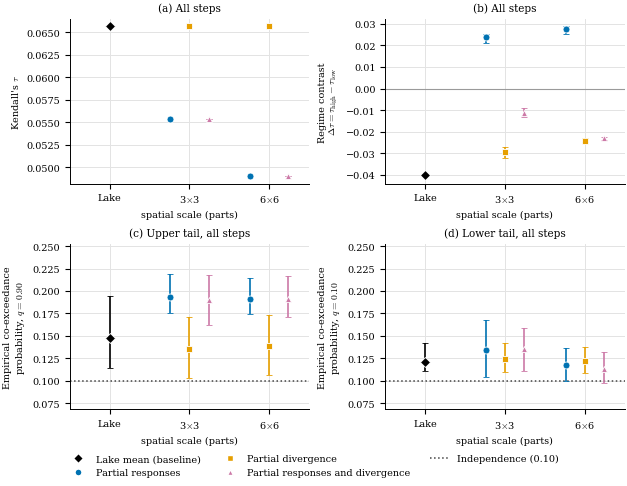

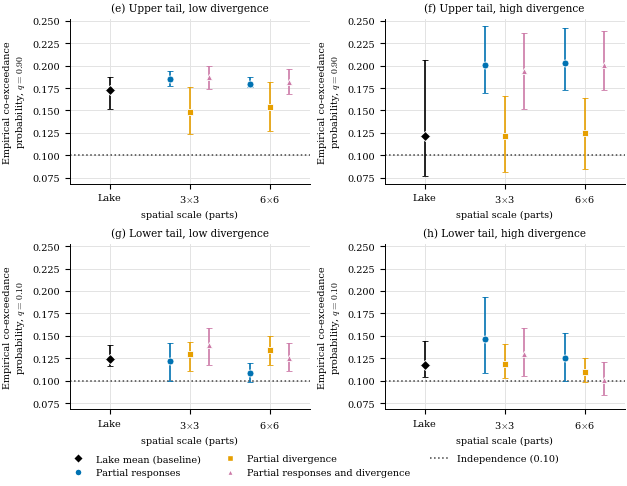

In [8]:
fig = plot_summary_top(results, os.path.join(plotting_core.IMAGES_DIR, "spatial_summary_top.png"))
plt.show()
fig = plot_summary_bottom(results, os.path.join(plotting_core.IMAGES_DIR, "spatial_summary_bottom.png"))
plt.show()

In [9]:
print("\n".join(reading_guide(results)))

(i) Does tau rise with the averaging area (mechanical effect)?
    lake: 0.066;  3x3 parts: 0.055;  6x6 parts: 0.049  (means over parts)
    31 of 45 parts lie within 2 standard errors of the lake value (typical SE of one tau: 0.015); mean part minus lake: -0.015.
    -> part values differ from the lake value by more than noise.

(ii)/(iii) Does the regime contrast delta tau = tau(high) - tau(low) persist, and does part-level divergence sharpen it?
    lake baseline: -0.040  (SE 0.028)
    partial responses: mean +0.027, 27 of 45 parts positive
    partial divergence: mean -0.025, 5 of 45 parts positive
    partial + partial: mean -0.021, 14 of 45 parts positive
    part-level vs lake-mean divergence: 32 of 45 parts give a larger delta tau; mean difference +0.015 (SE of one delta tau 0.028).
    -> differences are within noise: no evidence that the lake mean dilutes the regime signal.


## Preprocessing health

One full-sample AR/GARCH fit per series. Share of fits with GARCH persistence >= 0.98 and share whose standardised residuals fail a Ljung-Box test (p < 0.01 at any of lags 8, 16, 24).

In [10]:
health = runner.health_table()
if len(health):
    print((health[['persistence_flag', 'lb_flag']].mean() * 100).rename({'persistence_flag': '% persistence >= 0.98', 'lb_flag': '% Ljung-Box fail'}).round(0).to_string())
    print(f"fits: {len(health)}")
else:
    print("no fits in this session (all cases were read from the CSV)")

% persistence >= 0.98    24.0
% Ljung-Box fail         22.0
fits: 92


## Divergence plots

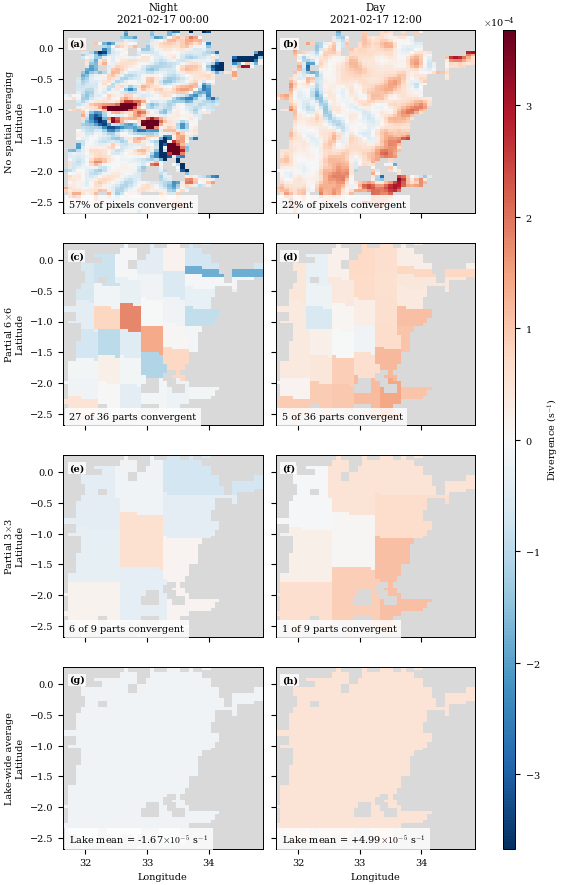

{'date': Timestamp('2021-02-17 00:00:00'), 'stamps': [Timestamp('2021-02-17 00:00:00'), Timestamp('2021-02-17 12:00:00')], 'lake_mean': [-1.6706847392375855e-05, 4.98709865732744e-05]}


In [11]:
info = plotting_lake.plot_divergence_scale_example(
    art['lakepts'], art['lon_sub'], art['lat_sub'], art['lake_sub'],
    time_valid, partitions=PARTS, date=None, hours=(0, 12), seed=6)
print(info)

## Save

In [12]:
save_artifact("spatial_aggregation", results=results, summary=summary,
              part_masks={k: [np.asarray(m) for m in v] for k, v in PARTS.items()})
print("Saved spatial_aggregation artifact; tables in", TABLES_DIR, "; figures in", plotting_core.IMAGES_DIR)

Saved spatial_aggregation artifact; tables in /home/users/hornstra/CODE FINALFINAL/Tables 07_sensitivity_analysis_spatial_aggregation ; figures in /home/users/hornstra/CODE FINALFINAL/Images 07_sensitivity_analysis_spatial_aggregation


## Table layout

Every table with a tabular is wrapped so that it shrinks to the text width when it is wider and is never enlarged (`reporting_tables.fit_all_tables`); no table needs a manual size edit in the report.

In [13]:
import reporting_tables
print('table files fitted to the text width:', reporting_tables.fit_all_tables())

table files fitted to the text width: []
